In [2]:
from math import sqrt
from scipy.stats import t

def welchs_t_test(group1, group2):
    mean1 = sum(group1) / len(group1)
    mean2 = sum(group2) / len(group2)
    var1 = sum((x - mean1) ** 2 for x in group1) / (len(group1) - 1)
    var2 = sum((x - mean2) ** 2 for x in group2) / (len(group2) - 1)
    n1, n2 = len(group1), len(group2)

    numerator = mean1 - mean2
    denominator = sqrt((var1 / n1) + (var2 / n2))
    t_stat = numerator / denominator

    df_num = ((var1 / n1) + (var2 / n2)) ** 2
    df_denom = ((var1**2) / (n1**2 * (n1 - 1))) + ((var2**2) / (n2**2 * (n2 - 1)))
    df_val = df_num / df_denom

    p_val = 2 * t.sf(abs(t_stat), df_val)

    return t_stat, df_val, p_val

**Mallows Euclidean**

In [64]:
from collections import defaultdict
import csv

results_by_phi = defaultdict(list)

with open("euclidean_mallows_accomplice.csv", newline='') as csvfile:
    reader = csv.reader(csvfile)
    next(reader)  # skip header

    for row in reader:
        phi1 = float(row[0])
        phi2 = float(row[1])
        count_woman = int(row[5])

        results_by_phi[(phi1, phi2)].append(count_woman)

group_A = results_by_phi[(1.0, 1.0)]
group_B = results_by_phi[(0.8, 1.0)]

t_stat = welchs_t_test(group_B, group_A)

print(f"t stat, df, p val:", t_stat)



t stat, df, p val: (-2.894018165123855, 994.4494172052624, 0.0038865375783330583)


**Reverse Euclidean**

In [55]:
from collections import defaultdict
import csv

results = defaultdict(list)

with open("reverse_Euclidean_two_for_one_results.csv", newline='') as csvfile:
    reader = csv.reader(csvfile)
    next(reader)  # skip header

    for row in reader:
        dimension = float(row[0])
        proportion = float(row[1])
        count_woman = int(row[10])

        results[(dimension, proportion)].append(count_woman)

group_A = results[(2, 1.0)]
group_B = results[(4, 1.0)]

t_stat = welchs_t_test(group_A, group_B)

print(f"t val, df val, p val:", t_stat)



t val, df val, p val: (0.8579015665359592, 196.29390524078642, 0.3919930951957845)


**Expectations Euclidean**

In [19]:
from collections import defaultdict
import csv

results = defaultdict(list)

with open("expectations_euclidean_gain_with_rank_diff.csv", newline='') as csvfile:
    reader = csv.reader(csvfile)
    next(reader)  # skip header

    for row in reader:
        dimension = float(row[0])
        std = float(row[1])
        count_woman = int(row[27])

        results[(dimension, std)].append(count_woman)

group_A = results[(2, 0.6)]
group_B = results[(2, 0.4)]

t_stat = welchs_t_test(group_A, group_B)

print(f"t val, df val, p val:", t_stat)



t val, df val, p val: (2.5560618745629182, 197.06681276268964, 0.011340007494908107)


**Mallows MD**

In [254]:
from collections import defaultdict
import csv

results_by_phi = defaultdict(list)

with open("mallows_MD_accomplice.csv", newline='') as csvfile:
    reader = csv.reader(csvfile)
    next(reader)  # skip header

    for row in reader:
        phi1 = float(row[0])
        phi2 = float(row[1])
        count_woman = int(row[9])

        results_by_phi[(phi1, phi2)].append(count_woman)

group_A = results_by_phi[(1.0, 1.0)]
group_B = results_by_phi[(1.0, 0.0)]

t_stat = welchs_t_test(group_A, group_B)

print(f"t val, df val, p val:", t_stat)



t val, df val, p val: (-1.005164241246284, 957.4999300328182, 0.31507171671896317)


**Mallows MA**

In [3]:
from collections import defaultdict
import csv

results_by_lattice_MA = defaultdict(list)

with open("mallows_MA_accomplice.csv", newline='') as csvfile:
    reader = csv.reader(csvfile)
    next(reader)  # skip header

    for row in reader:
        stable = int(row[7])
        self_woman = int(row[8])
        results_by_lattice_MA[(stable)].append(self_woman)

group_A = results_by_lattice_MA[(6)]
group_B = results_by_lattice_MA[(4)]

t_stat = welchs_t_test(group_A, group_B)

print(sum(group_A)/len(group_A), sum(group_B)/len(group_B))

print(f"t val, df val, p val:", t_stat)

#number_stable_matchings = results_by_lattice.keys()
#for num in range(30):
    #if num in number_stable_matchings:
        #group_num = results_by_lattice[(num)]
        #print(num, sum(group_num)/len(group_num))






12.817813765182187 10.111436950146627
t val, df val, p val: (5.096661631319288, 458.30145435809504, 5.06455572982915e-07)


**Mallows**

In [7]:
from collections import defaultdict
import csv

results_by_phi = defaultdict(list)

with open("mallows_accomplice.csv", newline='') as csvfile:
    reader = csv.reader(csvfile)
    next(reader)  # skip header

    for row in reader:
        phi1 = float(row[0])
        phi2 = float(row[1])
        count_woman = int(row[8])

        results_by_phi[(phi1, phi2)].append(count_woman)

group_A = results_by_phi[(1.0, 0.8)]
group_B = results_by_phi[(0.8, 1.0)]

t_stat = welchs_t_test(group_A, group_B)

print(f"t val, df val, p val:", t_stat)



t val, df val, p val: (-5.316175360349206, 940.0245655601349, 1.3242643448640712e-07)


In [9]:
from collections import defaultdict
import csv

results_by_lattice_mallows = defaultdict(list)

with open("mallows_accomplice.csv", newline='') as csvfile:
    reader = csv.reader(csvfile)
    next(reader)  # skip header

    for row in reader:
        stable = int(row[7])
        self_woman = int(row[8])
        results_by_lattice_mallows[(stable)].append(self_woman)

group_A = results_by_lattice_mallows[(6)]
group_B = results_by_lattice_mallows[(4)]

t_stat = welchs_t_test(group_A, group_B)

print(sum(group_A)/len(group_A), sum(group_B)/len(group_B))

print(f"t val, df val, p val:", t_stat)

number_stable_matchings = results_by_lattice.keys()
for num in range(30):
    if num in number_stable_matchings:
        group_num = results_by_lattice[(num)]
        #print(num, sum(group_num)/len(group_num))






3.2294520547945207 3.072375127420999
t val, df val, p val: (1.0510021693183977, 385.297213892328, 0.29391632089458264)


NameError: name 'results_by_lattice' is not defined

In [8]:
from collections import defaultdict
import csv

results_by_lattice_euclidean = defaultdict(list)

with open("reverse_euclidean_accomplice.csv", newline='') as csvfile:
    reader = csv.reader(csvfile)
    next(reader)  # skip header

    for row in reader:
        stable = int(row[7])
        self_woman = int(row[8])
        results_by_lattice_euclidean[(stable)].append(self_woman)

group_A = results_by_lattice_euclidean[(6)]
group_B = results_by_lattice_euclidean[(4)]

t_stat = welchs_t_test(group_A, group_B)

print(sum(group_A)/len(group_A), sum(group_B)/len(group_B))

print(f"t val, df val, p val:", t_stat)








1.322617680826636 0.9149085794655415
t val, df val, p val: (7.251190225650827, 1609.4240316756832, 6.390632563235999e-13)


In [7]:
from collections import defaultdict
import csv

results_by_lattice_mallows_MD = defaultdict(list)

with open("mallows_MD_accomplice.csv", newline='') as csvfile:
    reader = csv.reader(csvfile)
    next(reader)  # skip header

    for row in reader:
        stable = int(row[7])
        self_woman = int(row[8])
        results_by_lattice_mallows_MD[(stable)].append(self_woman)

group_A = results_by_lattice_mallows_MD[(6)]
group_B = results_by_lattice_mallows_MD[(4)]

t_stat = welchs_t_test(group_A, group_B)

print(sum(group_A)/len(group_A), sum(group_B)/len(group_B))

print(f"t val, df val, p val:", t_stat)








1.1160220994475138 0.8872549019607843
t val, df val, p val: (1.7457895093372915, 411.9934289789169, 0.08159294909776192)


In [6]:
from collections import defaultdict
import csv

results_by_lattice_mallows_euclidean = defaultdict(list)

with open("euclidean_mallows_accomplice.csv", newline='') as csvfile:
    reader = csv.reader(csvfile)
    next(reader)  # skip header

    for row in reader:
        stable = int(row[7])
        self_woman = int(row[8])
        results_by_lattice_mallows_euclidean[(stable)].append(self_woman)

group_A = results_by_lattice_mallows_euclidean[(6)]
group_B = results_by_lattice_mallows_euclidean[(4)]

t_stat = welchs_t_test(group_A, group_B)

print(sum(group_A)/len(group_A), sum(group_B)/len(group_B))

print(f"t val, df val, p val:", t_stat)








2.979591836734694 3.117921385742838
t val, df val, p val: (-1.3126311938176305, 1030.0275041835982, 0.18959964599416904)


In [5]:
from collections import defaultdict
import csv

results_by_lattice_expectations_euclidean = defaultdict(list)

with open("expectations_euclidean_accomplice.csv", newline='') as csvfile:
    reader = csv.reader(csvfile)
    next(reader)  # skip header

    for row in reader:
        stable = int(row[7])
        self_woman = int(row[8])
        results_by_lattice_expectations_euclidean[(stable)].append(self_woman)

group_A = results_by_lattice_expectations_euclidean[(6)]
group_B = results_by_lattice_expectations_euclidean[(4)]

t_stat = welchs_t_test(group_A, group_B)

print(sum(group_A)/len(group_A), sum(group_B)/len(group_B))

print(f"t val, df val, p val:", t_stat)








3.0 3.111495246326707
t val, df val, p val: (-0.917074916659688, 585.2890044501961, 0.3594811072759574)


In [26]:
from collections import defaultdict
import csv

results_by_lattice_fame_euclidean = defaultdict(list)

with open("fame_euclidean_accomplice.csv", newline='') as csvfile:
    reader = csv.reader(csvfile)
    next(reader)  # skip header

    for row in reader:
        stable = int(row[7])
        self_woman = int(row[8])
        results_by_lattice_fame_euclidean[(stable)].append(self_woman)

group_A = results_by_lattice_fame_euclidean[(6)]
group_B = results_by_lattice_fame_euclidean[(4)]

t_stat = welchs_t_test(group_A, group_B)

print(sum(group_A)/len(group_A), sum(group_B)/len(group_B))

print(f"t val, df val, p val:", t_stat)








ZeroDivisionError: division by zero

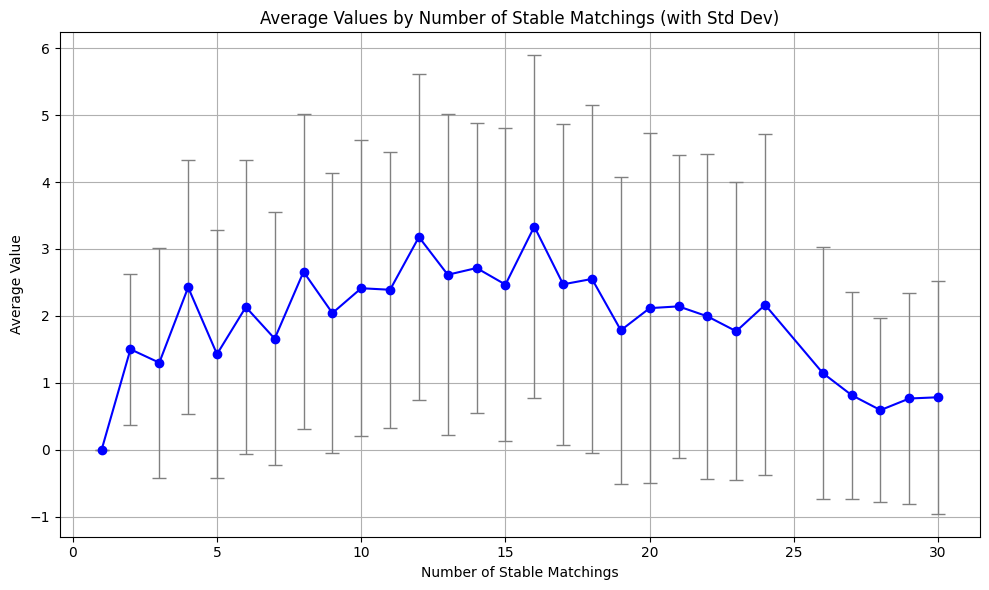

In [29]:
import matplotlib.pyplot as plt
import numpy as np

# Lists to store data
x_vals = []
y_vals = []
y_std = []

# Compute average and std deviation
number_stable_matchings = results_by_lattice_mallows.keys()
for num in range(31):
    if num in number_stable_matchings:
        group_num = results_by_lattice_mallows[num]
        group_num2 = results_by_lattice_euclidean[num]
        group_num3 = results_by_lattice_mallows_MD[num]
        group_num4 = results_by_lattice_mallows_euclidean[num]
        group_num5 = results_by_lattice_expectations_euclidean[num]
        sum_list = group_num + group_num2 + group_num3 + group_num4 + group_num5
        avg = np.mean(sum_list)
        std = np.std(sum_list)

        x_vals.append(num)
        y_vals.append(avg)
        y_std.append(std)

# Plot with error bars
plt.figure(figsize=(10, 6))
plt.errorbar(x_vals, y_vals, yerr=y_std, fmt='o-', capsize=5, color='blue', ecolor='gray', elinewidth=1)
plt.title('Average Values by Number of Stable Matchings (with Std Dev)')
plt.xlabel('Number of Stable Matchings')
plt.ylabel('Average Value')
plt.grid(True)
plt.tight_layout()
plt.show()

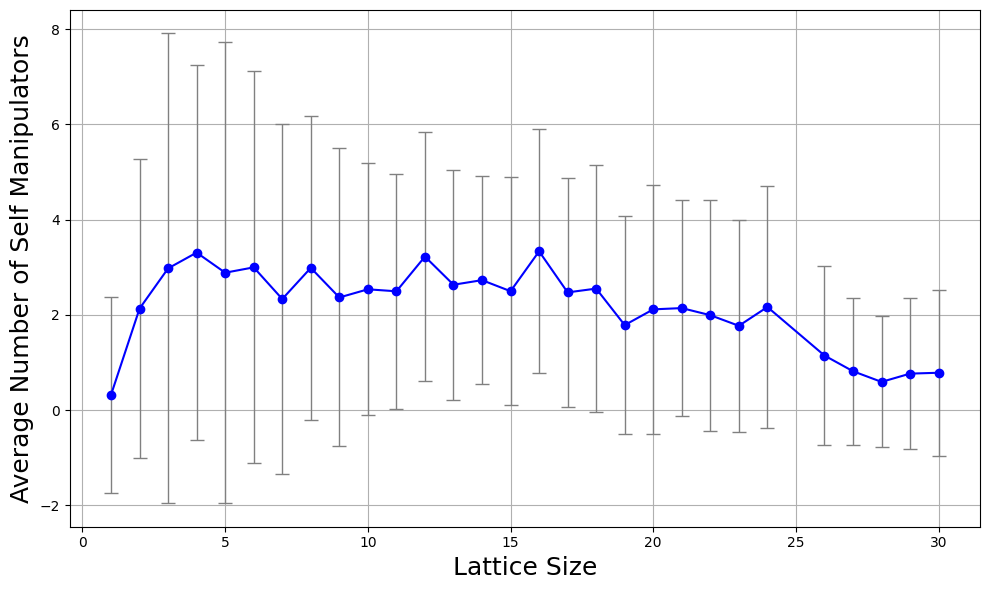

t val, df val, p val: (-0.21991473722105387, 1531.1652319686073, 0.8259668733079297)


In [12]:
from collections import defaultdict
import numpy as np
import matplotlib.pyplot as plt
from scipy.stats import ttest_ind  # Welch's t-test

# Dictionary to hold combined lists per number of stable matchings
combined_results = defaultdict(list)

x_vals = []
y_vals = []
y_std = []

# Populate combined_results with merged lists
number_stable_matchings = results_by_lattice_mallows.keys()
for num in range(31):
    if num in number_stable_matchings:
        group_num = results_by_lattice_mallows[num]
        group_num2 = results_by_lattice_euclidean[num]
        group_num3 = results_by_lattice_mallows_MD[num]
        group_num4 = results_by_lattice_mallows_euclidean[num]
        group_num5 = results_by_lattice_expectations_euclidean[num]
        group_num6 = results_by_lattice_MA[num]
        sum_list = group_num + group_num2 + group_num3 + group_num4 + group_num5 + group_num6
        combined_results[num] = sum_list

        avg = np.mean(sum_list)
        std = np.std(sum_list)

        x_vals.append(num)
        y_vals.append(avg)
        y_std.append(std)

# Plot the results with error bars
plt.figure(figsize=(10, 6))
plt.errorbar(x_vals, y_vals, yerr=y_std, fmt='o-', capsize=5, color='blue', ecolor='gray', elinewidth=1)
plt.xlabel('Lattice Size', fontsize = 18)
plt.ylabel('Average Number of Self Manipulators', fontsize = 18)
plt.grid(True)
plt.tight_layout()
plt.savefig("total_lattice_plot.pdf")
plt.show()

# --- Welch's t-test between two groups ---
group_A = combined_results[29]
group_B = combined_results[30]

# Perform Welch's t-test
t_stat = welchs_t_test(group_A, group_B)

# Print results
print(f"t val, df val, p val:", t_stat)


**For n = 10**

In [6]:
from collections import defaultdict
import csv

results_by_lattice_reverse_euclidean = defaultdict(list)

with open("reverse_euclidean_gain.csv", newline='') as csvfile:
    reader = csv.reader(csvfile)
    next(reader)  # skip header

    for row in reader:
        stable = int(row[12])
        self_woman = int(row[10])
        results_by_lattice_reverse_euclidean[(stable)].append(self_woman)

In [7]:
results_by_lattice_expectations_euclidean = defaultdict(list)

with open("expectations_euclidean_gain.csv", newline='') as csvfile:
    reader = csv.reader(csvfile)
    next(reader)  # skip header

    for row in reader:
        stable = int(row[12])
        self_woman = int(row[10])
        results_by_lattice_expectations_euclidean[(stable)].append(self_woman)

In [8]:
results_by_lattice_mallows_euclidean = defaultdict(list)

with open("mallows_euclidean_gain.csv", newline='') as csvfile:
    reader = csv.reader(csvfile)
    next(reader)  # skip header

    for row in reader:
        stable = int(row[12])
        self_woman = int(row[10])
        results_by_lattice_mallows_euclidean[(stable)].append(self_woman)

In [9]:
results_by_lattice_mallows = defaultdict(list)

with open("mallows_gain.csv", newline='') as csvfile:
    reader = csv.reader(csvfile)
    next(reader)  # skip header

    for row in reader:
        stable = int(row[12])
        self_woman = int(row[10])
        results_by_lattice_mallows[(stable)].append(self_woman)

In [10]:
results_by_lattice_mallows_MD = defaultdict(list)

with open("mallows_MD_gain.csv", newline='') as csvfile:
    reader = csv.reader(csvfile)
    next(reader)  # skip header

    for row in reader:
        stable = int(row[12])
        self_woman = int(row[10])
        results_by_lattice_mallows_MD[(stable)].append(self_woman)

In [13]:
results_by_lattice_mallows_MA = defaultdict(list)

with open("mallows_MA_gain.csv", newline='') as csvfile:
    reader = csv.reader(csvfile)
    next(reader)  # skip header

    for row in reader:
        stable = int(row[24])
        self_woman = int(row[10])
        results_by_lattice_mallows_MA[(stable)].append(self_woman)

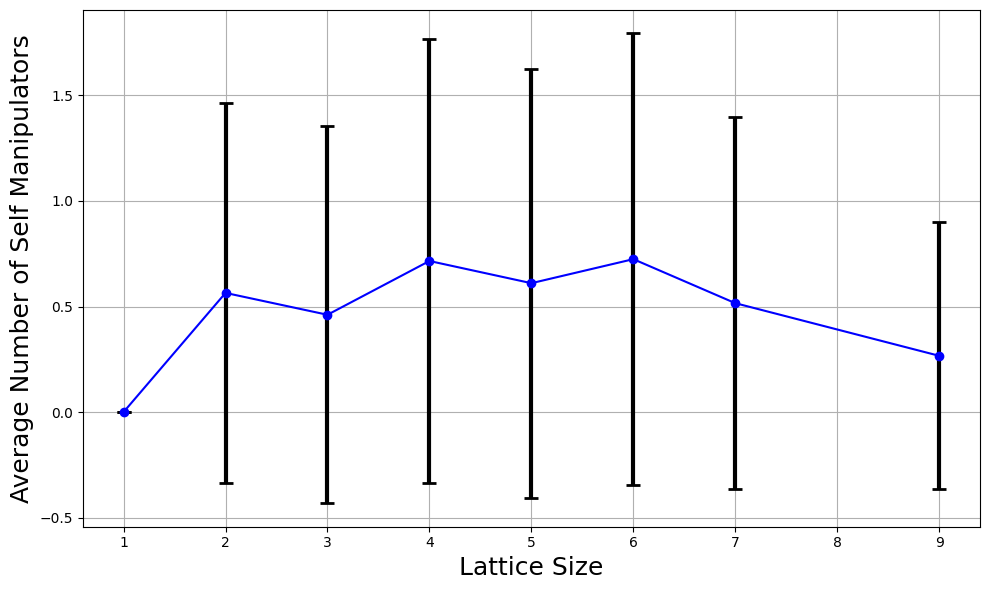

In [18]:
from collections import defaultdict
import numpy as np
import matplotlib.pyplot as plt
from scipy.stats import ttest_ind  # Welch's t-test

# Dictionary to hold combined lists per number of stable matchings
combined_results = defaultdict(list)

x_vals = []
y_vals = []
y_std = []

# Populate combined_results with merged lists
number_stable_matchings = results_by_lattice_mallows.keys()
for num in range(31):
    if num in number_stable_matchings:
        group_num = results_by_lattice_mallows[num]
        group_num2 = results_by_lattice_reverse_euclidean[num]
        group_num3 = results_by_lattice_mallows_MD[num]
        group_num4 = results_by_lattice_mallows_euclidean[num]
        group_num5 = results_by_lattice_expectations_euclidean[num]
        group_num6 = results_by_lattice_mallows_MA[num]
        sum_list = group_num + group_num2 + group_num3 + group_num4 + group_num5 + group_num6
        combined_results[num] = sum_list

        avg = np.mean(sum_list)
        std = np.std(sum_list)

        x_vals.append(num)
        y_vals.append(avg)
        y_std.append(std)

# Plot the results with error bars
plt.figure(figsize=(10, 6))
plt.errorbar(x_vals, y_vals, yerr=y_std, fmt='o-', capsize=5, color='blue', ecolor='black', elinewidth=3, capthick=2)
plt.xlabel('Lattice Size', fontsize = 18)
plt.ylabel('Average Number of Self Manipulators', fontsize = 18)
plt.grid(True)
plt.tight_layout()
plt.savefig("total_lattice_plot_10.pdf")
plt.show()